# GameTheory-11c-Raffinements-Sequentiels-Python

**Navigation** : [<< 11-BayesianGames](GameTheory-11-BayesianGames-Python.ipynb) | [11b-Lean-BayesianGamesExt](GameTheory-11b-Lean-BayesianGamesExt-Lean.ipynb) | [12-ReputationGames >>](GameTheory-12-ReputationGames-Python.ipynb)

## Objectifs

Le palier 11 a pose les croyances comme objet d'equilibre. Ce carnet les **raffine** : que vaut une croyance placee sur un noeud que le jeu n'atteint jamais, et jusqu'ou une telle liberte est-elle acceptable ?

A la fin de ce carnet, vous saurez :

1. representer un jeu a information imparfaite par ses **historiques** et calculer un paiement espere conditionnel ;
2. tester la **rationalite sequentielle** (Bonanno, Definition 10.2) et reconnaitre un **equilibre sequentiel faible** (WSE) ;
3. construire une **suite completement melangee** et lire la limite des croyances bayesiennes — le test de Kreps-Wilson (1982) ;
4. verifier un **ordre de plausibilite** au sens AGM (proprietes P1/P2) et la coherence bayesienne relative (B1-B3) ;
5. mesurer sur un meme arbre ce que chaque notion accepte et ce qu'elle refuse.

**Source doctrinale** : G. Bonanno, *Game Theory* (arXiv 1512.06808), chapitres 10 (equilibre sequentiel faible), 11 (equilibre sequentiel) et 12 (equilibre bayesien parfait).

> **Note de fidelite a la source.** Les figures du chapitre 12 portent leurs paiements sous forme de dessins ; la copie texte consultee ne permet pas de les reconstituer chiffre par chiffre. Ce carnet **construit donc son propre jeu**, de meme forme (trois joueurs, deux etapes, un ensemble d'information a quatre noeuds), et **recalcule** les arguments du livre — les theoremes cites (Th 10.1, Th 11.1, Th 12.1, Th 12.2, Th 12.5) sont attribues a leur auteur ; les nombres sont les notres, et chaque verdict affiche ici est produit par le code de ce carnet, pas recopie.

In [1]:
# Configuration et imports
import itertools
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["font.size"] = 9
np.set_printoptions(precision=4, suppress=True)

print("numpy", np.__version__, "| matplotlib", plt.matplotlib.__version__)

numpy 2.2.6 | matplotlib 3.11.2


## 1. Pourquoi l'equilibre de Nash ne suffit pas

Un equilibre de Nash selectionne un **profil de strategies** : il ne dit rien de ce qu'un joueur *croit* au moment de jouer, ni de ce qu'il ferait dans une branche que personne n'emprunte. Sur un arbre, ces deux silences laissent passer des profils peu credibles : une menace qui ne serait jamais executee, une croyance placee sur un noeud inatteignable pour justifier n'importe quel coup.

Les raffinements successifs repondent chacun a une partie du probleme :

| Notion | Ce qu'elle ajoute | Chapitre |
|---|---|---|
| Nash (NE) | optimalite ex ante, aucune croyance | 5-6 |
| Sous-jeu parfait (SPE) | optimalite dans chaque sous-jeu, aucun sous-jeu pour l'information imparfaite | 10 |
| Séquentiel faible (WSE) | rationalite sequentielle **a chaque ensemble d'information** + Bayes la ou le jeu passe | 10 |
| Séquentiel (SE) | WSE + croyances atteignables comme **limites** de suites completement melangees | 11 |
| Bayésien parfait (PBE) | rationalite sequentielle + croyances **rationalisees** par un ordre de plausibilite (AGM) | 12 |

La chaine n'est pas une tour de poupees : Bonanno demontre que **WSE et SPE sont incomparables** (Fig. 10.9), que **SE est un raffinement de WSE** (Rem. 11.1) et de **SPE** (Th. 11.1), que **PBE raffine SPE et WSE** (Th. 12.1) et que **SE implique PBE** (Th. 12.2). L'objet de ce carnet est de rendre chacun de ces echarts **calculable** sur un seul arbre.

### 1.1 L'arbre pivot

Trois joueurs, deux etapes :

- **J1** joue a la racine : `a`, `b` ou `c` (`c` termine le jeu) ;
- **J2** joue en information imparfaite : elle ne sait pas si J1 a joue `a` ou `b` — un ensemble d'information a deux noeuds, actions `d` et `e` ;
- **J3** joue en information imparfaite sur quatre noeuds `{ad, ae, bd, be}`, actions `f` et `g`.

Neuf historiques terminaux : `c`, et `{a,b} x {d,e} x {f,g}`. C'est la forme minimale qui separe les trois notions : deux croyances libres (l'ensemble de J2 et celui de J3 sont hors du chemin quand J1 joue `c`), un couplage entre elles (l'historique `be` relie les deux), et donc de la place pour un desaccord entre « ce que Bayes impose » et « ce qu'un ordre de plausibilite autorise ».

In [2]:
# ----------------------------------------------------------------
# Arbre : les noeuds sont des historiques (tuples d'actions).
#   ("decision", joueur, info_set, [(action, enfant), ...])
#   ("terminal",)
# ----------------------------------------------------------------
RACINE = ()
FEUILLES_I3 = [("a", "d"), ("a", "e"), ("b", "d"), ("b", "e")]

def construire_arbre():
    arbre = {
        RACINE: ("decision", 1, "I1", [("a", ("a",)), ("b", ("b",)), ("c", ("c",))]),
        ("a",): ("decision", 2, "I2", [("d", ("a", "d")), ("e", ("a", "e"))]),
        ("b",): ("decision", 2, "I2", [("d", ("b", "d")), ("e", ("b", "e"))]),
    }
    for h in FEUILLES_I3:
        arbre[h] = ("decision", 3, "I3", [("f", h + ("f",)), ("g", h + ("g",))])
    for t in [("c",)] + [h + (a,) for h in FEUILLES_I3 for a in ("f", "g")]:
        arbre[t] = ("terminal",)
    return arbre

ARBRE = construire_arbre()
HISTORIQUES = list(ARBRE)
TERMINAUX = [h for h in HISTORIQUES if ARBRE[h][0] == "terminal"]

# Paiements (u1, u2, u3) - variante alpha, celle du chapitre 12.1
PAYOFFS_ALPHA = {
    ("c",):        (3, 0, 0),
    ("a", "d", "f"): (1, 2, 0), ("a", "d", "g"): (0, 2, 2),
    ("a", "e", "f"): (0, 1, 0), ("a", "e", "g"): (0, 1, 2),
    ("b", "d", "f"): (0, 2, 0), ("b", "d", "g"): (0, 2, 2),
    ("b", "e", "f"): (0, 1, 4), ("b", "e", "g"): (0, 1, 0),
}

print(f"{len(HISTORIQUES)} historiques, {len(TERMINAUX)} terminaux")
for t in TERMINAUX:
    print(f"  {t!s:20s} -> {PAYOFFS_ALPHA[t]}")

16 historiques, 9 terminaux
  ('c',)               -> (3, 0, 0)
  ('a', 'd', 'f')      -> (1, 2, 0)
  ('a', 'd', 'g')      -> (0, 2, 2)
  ('a', 'e', 'f')      -> (0, 1, 0)
  ('a', 'e', 'g')      -> (0, 1, 2)
  ('b', 'd', 'f')      -> (0, 2, 0)
  ('b', 'd', 'g')      -> (0, 2, 2)
  ('b', 'e', 'f')      -> (0, 1, 4)
  ('b', 'e', 'g')      -> (0, 1, 0)


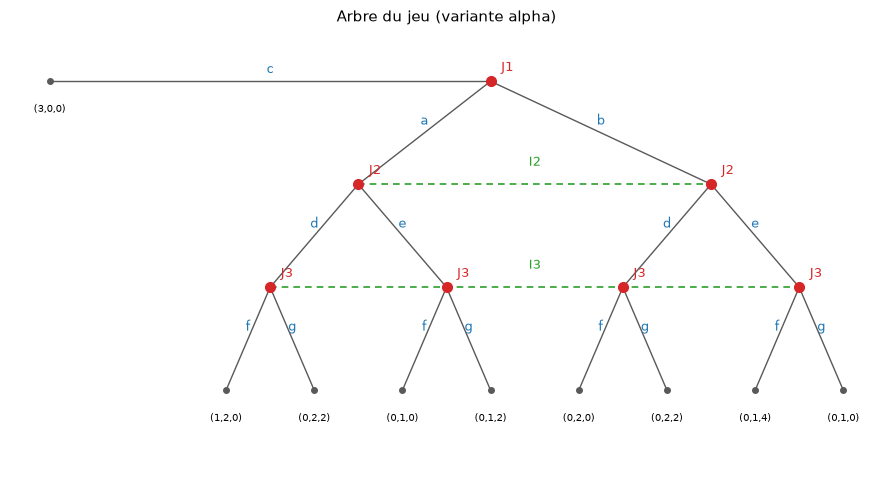

Ensembles d'information : {'I1': [()], 'I2': [('a',), ('b',)], 'I3': [('a', 'd'), ('a', 'e'), ('b', 'd'), ('b', 'e')]}


In [3]:
def dessiner_arbre(payoffs, titre="Arbre du jeu (variante alpha)"):
    """Dessine l'arbre, avec les ensembles d'information en pointilles."""
    x = {("c",): -1.0,
         ("a", "d", "f"): 1.0, ("a", "d", "g"): 2.0,
         ("a", "e", "f"): 3.0, ("a", "e", "g"): 4.0,
         ("b", "d", "f"): 5.0, ("b", "d", "g"): 6.0,
         ("b", "e", "f"): 7.0, ("b", "e", "g"): 8.0}
    x[("a", "d")] = 1.5
    x[("a", "e")] = 3.5
    x[("b", "d")] = 5.5
    x[("b", "e")] = 7.5
    x[("a",)] = 2.5
    x[("b",)] = 6.5
    x[RACINE] = 4.0
    y = {RACINE: 3.0, ("a",): 2.0, ("b",): 2.0, ("c",): 3.0}
    for h in FEUILLES_I3:
        y[h] = 1.0
        y[h + ("f",)] = 0.0
        y[h + ("g",)] = 0.0

    fig, ax = plt.subplots()
    for h, noeud in ARBRE.items():
        if noeud[0] != "decision":
            continue
        for a, enfant in noeud[3]:
            ax.plot([x[h], x[enfant]], [y[h], y[enfant]], color="0.35", lw=1.0, zorder=1)
            ax.text((x[h] + x[enfant]) / 2, (y[h] + y[enfant]) / 2 + 0.05, a,
                    ha="center", va="bottom", fontsize=9, color="C0")
    for h, noeud in ARBRE.items():
        if noeud[0] == "terminal":
            ax.plot(x[h], y[h], "o", color="0.35", ms=4, zorder=2)
            u1, u2, u3 = payoffs[h]
            ax.text(x[h], y[h] - 0.22, f"({u1},{u2},{u3})", ha="center", va="top", fontsize=7.5)
        else:
            ax.plot(x[h], y[h], "o", color="C3", ms=7, zorder=3)
            ax.text(x[h] + 0.12, y[h] + 0.10, f"J{noeud[1]}", fontsize=9, color="C3")

    # ensembles d'information
    for iset, hs in info_sets(ARBRE).items():
        xs = [x[h] for h in hs]
        ys = [y[h] for h in hs]
        if len(hs) > 1:
            ax.plot([min(xs), max(xs)], [ys[0], ys[-1]], ls=(0, (4, 3)), color="C2", lw=1.2, zorder=0)
            ax.text((min(xs) + max(xs)) / 2, ys[0] + 0.18, iset, ha="center", fontsize=9, color="C2")
    ax.set_title(titre)
    ax.axis("off")
    ax.set_ylim(-0.9, 3.5)
    plt.tight_layout()
    plt.show()


def info_sets(arbre=ARBRE):
    """{info_set: [historiques]}, historiques tries par longueur puis ordre alphabetique."""
    res = {}
    for h in sorted(arbre, key=lambda h: (len(h), h)):
        if arbre[h][0] == "decision":
            res.setdefault(arbre[h][2], []).append(h)
    return res


dessiner_arbre(PAYOFFS_ALPHA)
print("Ensembles d'information :", {k: v for k, v in info_sets().items()})

### 1.2 Assessment et rationalite sequentielle

Un **assessment** est un couple $(\sigma, \mu)$ : une strategie de comportement (une probabilite sur les actions de chaque ensemble d'information) et un systeme de croyances (une distribution sur les noeuds de chaque ensemble d'information).

> **Definition 10.2 (Bonanno).** $\sigma$ est *sequentiellement rationnelle* si, a **chaque** ensemble d'information $H$, le joueur ne peut pas augmenter son paiement conditionnel en changeant son choix en $H$ **et** en tout ensemble d'information futur qu'il controle.

La clause « et en tout ensemble futur » est la partie qu'on oublie, et c'est elle qui fait la force de la notion. Bonanno l'illustre (Fig. 10.2) : une strategie $(c, e)$ peut etre localement optimale en $\{x,y\}$ — donc optimale dans chaque ensemble pris isolement — et pourtant battue si le joueur change **aussi** son plan en $\{s,t\}$. Retenir « localement optimal » donnerait un faux raffinement ; la definition exige un changement de strategie **entiere**.

In [4]:
def payoff_espere(h, joueur, sigma, payoffs, arbre=ARBRE):
    """Paiement espere du joueur a partir de l'historique h, sous sigma."""
    noeud = arbre[h]
    if noeud[0] == "terminal":
        return payoffs[h][joueur - 1]
    _, _, iset, enfants = noeud
    return sum(sigma[(iset, a)] * payoff_espere(e, joueur, sigma, payoffs, arbre) for a, e in enfants)


def proba_atteinte(h, sigma, arbre=ARBRE):
    """P(h) : produit des probabilites des actions du chemin."""
    p = 1.0
    for i in range(len(h)):
        iset = arbre[h[:i]][2]
        p *= sigma[(iset, h[i])]
    return p


def croyances_bayesiennes(sigma, arbre=ARBRE):
    """Mu par mise a jour bayesienne. None = ensemble d'information non atteint (croyance libre)."""
    mu = {}
    for iset, hs in info_sets(arbre).items():
        total = sum(proba_atteinte(h, sigma, arbre) for h in hs)
        for h in hs:
            mu[h] = proba_atteinte(h, sigma, arbre) / total if total > 1e-12 else None
    return mu


def seq_rationnel(sigma, mu, payoffs, arbre=ARBRE, tol=1e-9):
    """Def 10.2 : a chaque info set, la valeur du melange joue est maximale.
    mu doit etre defini (float) sur tous les noeuds."""
    violations = []
    for iset, hs in info_sets(arbre).items():
        joueur = arbre[hs[0]][1]
        actions = [a for a, _ in arbre[hs[0]][3]]
        valeurs = {a: sum(mu[h] * payoff_espere(h + (a,), joueur, sigma, payoffs, arbre) for h in hs)
                   for a in actions}
        valeur_melange = sum(sigma[(iset, a)] * valeurs[a] for a in actions)
        ecart = max(valeurs.values()) - valeur_melange
        if ecart > tol:
            violations.append({"info_set": iset, "valeurs": valeurs, "ecart": ecart})
    return violations


def sigma_depuis(choix):
    """Strategie de comportement pure : choix = {info_set: action}."""
    sigma = {}
    for iset, hs in info_sets().items():
        for a, _ in ARBRE[hs[0]][3]:
            sigma[(iset, a)] = 1.0 if a == choix[iset] else 0.0
    return sigma


print("Moteur charge : payoff_espere, proba_atteinte, croyances_bayesiennes, seq_rationnel, sigma_depuis")

Moteur charge : payoff_espere, proba_atteinte, croyances_bayesiennes, seq_rationnel, sigma_depuis


## 2. Un premier assessment : `(c, d, f)` avec la croyance `be` certaine

Prenons $\sigma = (c,\ d,\ f)$ — J1 termine, J2 joue `d`, J3 joue `f` — et posons $\mu(be) = 1$ : J3 croit dur comme fer qu'il se trouve en `be`. C'est le genre de croyance qu'aucune observation ne peut lui fournir, puisque le jeu s'arrete en `c` ; mais rien, dans la definition d'un WSE, ne l'interdit.

Verifions ce que les paiements disent. Sur la variante $\alpha$, J3 prefere `g` en `ad`, `ae` et `bd` ($2 > 0$) ; en `be` il prefere `f` ($4 > 0$). Sa croyance `be` certaine rend donc `f` optimal, et le profil passe le test de rationalite sequentielle.

In [5]:
SIGMA_A = sigma_depuis({"I1": "c", "I2": "d", "I3": "f"})
MU_A = {}
for iset, hs in info_sets().items():
    for h in hs:
        MU_A[h] = 1.0 if h == ("b", "e") else 0.0

print("Croyances de A :", MU_A)
print("Bayes sous sigma_A (None = non atteint) :", croyances_bayesiennes(SIGMA_A))

violations = seq_rationnel(SIGMA_A, MU_A, PAYOFFS_ALPHA)
print("\nViolations de rationalite sequentielle :", violations if violations else "aucune")

# Detail des valeurs au dernier ensemble d'information
for iset, hs in info_sets().items():
    joueur = ARBRE[hs[0]][1]
    actions = [a for a, _ in ARBRE[hs[0]][3]]
    vals = {a: round(sum(MU_A[h] * payoff_espere(h + (a,), joueur, SIGMA_A, PAYOFFS_ALPHA) for h in hs), 3)
            for a in actions}
    print(f"  {iset} (J{joueur}) : {vals}  -> joue {[a for a in actions if SIGMA_A[(iset, a)] > 0][0]}")

Croyances de A : {(): 0.0, ('a',): 0.0, ('b',): 0.0, ('a', 'd'): 0.0, ('a', 'e'): 0.0, ('b', 'd'): 0.0, ('b', 'e'): 1.0}
Bayes sous sigma_A (None = non atteint) : {(): 1.0, ('a',): None, ('b',): None, ('a', 'd'): None, ('a', 'e'): None, ('b', 'd'): None, ('b', 'e'): None}

Violations de rationalite sequentielle : aucune
  I1 (J1) : {'a': 0.0, 'b': 0.0, 'c': 0.0}  -> joue c
  I2 (J2) : {'d': 0.0, 'e': 0.0}  -> joue d
  I3 (J3) : {'f': 4.0, 'g': 0.0}  -> joue f


### 2.1 La definition du WSE

> **Definition 10.4 (Bonanno).** $\mu$ est *bayesiennement coherent* avec $\sigma$ si, pour tout ensemble d'information $H$ **atteint avec probabilite positive**, $\mu(x) = P^{\sigma}(x) / P^{\sigma}(H)$.
>
> **Definition 10.5.** Un **equilibre sequentiel faible** est un assessment sequentiellement rationnel dont les croyances sont bayesiennement coherentes.

Le mot decisif est « atteint ». Hors du chemin, $\mu$ est **libre** : la definition ne lui impose rien. C'est exactement la porte par laquelle passe l'assessment `A`, et c'est aussi la faiblesse que le chapitre 11 va refermer.

Cherchons maintenant **tous** les WSE purs du jeu, en laissant le programme faire le travail : pour chaque profil pur, on calcule les croyances imposees par Bayes la ou le jeu passe, et on cherche, sur une grille, des croyances libres qui rendent le profil sequentiellement rationnel.

In [6]:
def grille_simplexe(n, pas=0.25):
    """Toutes les distributions sur n points, au pas donne."""
    k = int(round(1 / pas))
    if n == 1:
        yield (1.0,)
        return
    for comb in itertools.product(range(k + 1), repeat=n - 1):
        if sum(comb) <= k:
            yield tuple(c / k for c in comb) + ((k - sum(comb)) / k,)


def est_wse(sigma, payoffs, pas=0.25, arbre=ARBRE):
    """Existe-t-il des croyances (Bayes la ou le jeu passe, libres ailleurs)
    rendant sigma sequentiellement rationnelle ?"""
    base = croyances_bayesiennes(sigma, arbre)
    sets = info_sets(arbre)
    libres = [i for i, hs in sets.items() if base[hs[0]] is None]
    jeux = [list(grille_simplexe(len(sets[i]), pas)) for i in libres]
    for comb in (itertools.product(*jeux) if jeux else [()]):
        mu = dict(base)
        for i, vect in zip(libres, comb):
            for h, w in zip(sets[i], vect):
                mu[h] = w
        if not seq_rationnel(sigma, mu, payoffs, arbre):
            return True, mu
    return False, None


wse_purs = []
for x in "abc":
    for y in "de":
        for z in "fg":
            choix = {"I1": x, "I2": y, "I3": z}
            ok, mu = est_wse(sigma_depuis(choix), PAYOFFS_ALPHA)
            if ok:
                wse_purs.append((x + y + z, {h: round(w, 2) for h, w in mu.items() if w}))

print(f"{len(wse_purs)} equilibres sequentiels faibles purs sur 12 profils :")
for profil, mu in wse_purs:
    print(f"  sigma = {profil:3s}  croyances porteuses : {mu}")

2 equilibres sequentiels faibles purs sur 12 profils :
  sigma = cdf  croyances porteuses : {(): 1.0, ('b',): 1.0, ('b', 'e'): 1.0}
  sigma = cdg  croyances porteuses : {(): 1.0, ('b',): 1.0, ('b', 'd'): 0.75, ('b', 'e'): 0.25}


### 2.2 Ce que le WSE accepte

Deux choses sont a lire dans cette enumeration.

**Le WSE est permissif hors du chemin.** Le profil `cdf` passe avec $\mu(be) = 1$ comme avec n'importe quelle autre croyance sur $\{ad,ae,bd,be\}$ : l'ensemble d'information n'est jamais atteint, donc Bayes ne dit rien, et la rationalite sequentielle se satisfait d'**une** croyance favorable. Un equilibre qui repose sur une croyance qu'aucune histoire du jeu ne produirait est donc un WSE parfaitement legal.

**Le WSE n'est pas une variante du SPE.** Bonanno (Fig. 10.9) donne un jeu ou un WSE n'est pas sous-jeu parfait, et la Fig. 10.8 un SPE qui n'est aucun WSE : les deux ensembles se croisent sans contenir l'un l'autre. Un WSE n'implique pas de credibilite dans les sous-jeux, un SPE ne dit rien des croyances aux ensembles d'information qui ne sont pas des sous-jeux. Ce carnet ne peut pas montrer ce croisement sur son arbre (il n'a aucun sous-jeu propre) : c'est un resultat cite, que le chapitre 10 etablit sur des arbres a deux branches.

## 3. L'equilibre sequentiel : exiger des croyances atteignables

Kreps et Wilson (1982) referment la porte laissee ouverte : une croyance placee sur un noeud inatteignable doit etre **la limite** de croyances qu'un jeu legerement bruite produirait.

> **Definition 11.1 (Bonanno).** $\mu$ est *KW-coherent* avec $\sigma$ s'il existe une suite de strategies **completement melangees** $\sigma_n \to \sigma$ telle que les croyances bayesiennes $\mu_n$ associees convergent vers $\mu$.
>
> **Definition 11.2.** Un **equilibre sequentiel** est un assessment sequentiellement rationnel dont les croyances sont KW-coherentes.

L'idee est de rendre la menace credible *par construction* : si chaque action du jeu est jouee avec une probabilite strictement positive, chaque ensemble d'information est atteint, Bayes y determine les croyances sans ambiguite, et la croyance limite herite de ce que le bruit impose — pas de ce que l'analyste a bien voulu poser.

Bonanno (§11.3) en donne aussi la critique : la limite depend du **chemin** suivi par la suite, et deux suites differentes peuvent converger vers deux croyances differentes ; l'objet n'a pas la simplicite qu'on lui prete (il cite Kreps et Wilson eux-memes, p. 876, et Osborne-Rubinstein 1994, p. 225). Et le SE **n'elimine pas** les strategies faiblement dominees (Fig. 11.6) : le trembling-hand de Selten (1975) est un raffinement plus fort, hors de notre perimetre.

Testons $A$. Une suite completement melangee qui converge vers $(c,d,f)$ doit jouer `e` avec une probabilite qui tend vers 0, et `b` aussi. Or $P(be) = \sigma(b)\,\sigma(e)$ : le produit de deux quantites qui tendent vers zero. Sa croyance limite ne peut donc pas valoir 1.

In [7]:
def sigma_eps(eps):
    """Suite completement melangee convergeant vers (c, d, f)."""
    return {
        ("I1", "a"): eps, ("I1", "b"): eps, ("I1", "c"): 1 - 2 * eps,
        ("I2", "d"): 1 - eps, ("I2", "e"): eps,
        ("I3", "f"): 1 - eps, ("I3", "g"): eps,
    }


print("eps      sigma_a  sigma_b  sigma_c   P(be)     mu(be)    mu(a)")
for eps in (1e-1, 1e-2, 1e-3, 1e-4, 1e-6):
    s = sigma_eps(eps)
    mu = croyances_bayesiennes(s)
    print(f"{eps:<8g} {s[('I1','a')]:<8g} {s[('I1','b')]:<8g} {s[('I1','c')]:<9g} "
          f"{proba_atteinte(('b','e'), s):<9.3e} {mu[('b','e')]:<9.6f} {mu[('a',)]:.6f}")

print("\nLa croyance exigee par l'assessment A est mu(be) = 1.")
print("Le long de TOUTE suite melangee convergeant vers (c,d,f), mu(be) -> 0.")
print("=> aucune suite ne produit la croyance de A : A n'est pas KW-coherent, donc pas SE.")

eps      sigma_a  sigma_b  sigma_c   P(be)     mu(be)    mu(a)
0.1      0.1      0.1      0.8       1.000e-02 0.050000  0.500000
0.01     0.01     0.01     0.98      1.000e-04 0.005000  0.500000
0.001    0.001    0.001    0.998     1.000e-06 0.000500  0.500000
0.0001   0.0001   0.0001   0.9998    1.000e-08 0.000050  0.500000
1e-06    1e-06    1e-06    0.999998  1.000e-12 0.000000  0.500000

La croyance exigee par l'assessment A est mu(be) = 1.
Le long de TOUTE suite melangee convergeant vers (c,d,f), mu(be) -> 0.
=> aucune suite ne produit la croyance de A : A n'est pas KW-coherent, donc pas SE.


### 3.1 Verdict sur `A`

La croyance $\mu(be)=1$ etait libre pour le WSE, elle est **inatteignable** pour le SE : il faudrait que `b` et `e` soient joues avec une probabilite non nulle a la limite, ce qui contredit la convergence vers $(c,d,f)$. Le test ne demande meme pas de discussion sur les paiements — c'est une propriete du **transport des croyances**, independante de l'echelle des gains.

C'est un point important pour la suite : la frontiere entre WSE et SE ne se joue pas sur ce que les joueurs preferent, mais sur ce que l'observation peut leur apprendre. Un equilibre peut etre parfaitement rationnel et reposer sur une croyance que le jeu, tel qu'il est joue, ne peut pas engendrer.

Reste une troisieme voie, celle du chapitre 12 : ne pas exiger que la croyance soit une **limite**, mais exiger qu'elle soit **justifiee par une politique de revision** — un ordre de plausibilite. C'est la notion d'equilibre bayesien parfait.

## 4. L'equilibre bayesien parfait (version AGM)

Bonanno construit le PBE sur la theorie AGM de la revision des croyances (Alchourron, Gardenfors, Makinson, 1985) : un **ordre de plausibilite** $\preceq$ sur les historiques, ou $h \preceq h'$ se lit « $h$ est au moins aussi plausible que $h'$ ».

> **Definition 12.1.** $\preceq$ est un ordre de plausibilite s'il est total et transitif et satisfait, pour tout historique de decision $h$ :
> - **PL1** : pour toute action $a \in A(h)$, $h \preceq ha$ ;
> - **PL2** : (i) il existe $a$ tel que $h \sim ha$ ; (ii) si $h \sim ha$ alors $h' \sim h'a$ pour tout $h' \in I(h)$ ;
> - **PL3** : si $h$ est un noeud de la nature, $h \sim ha$ pour toute action.

> **Definition 12.2.** $(\sigma,\mu)$ est **AGM-coherent** s'il existe un ordre $\preceq$ tel que, pour tout $h \in D$ et $a \in A(h)$ :
> - **P1** : $\sigma(a) > 0$ **si et seulement si** $h \sim ha$ ;
> - **P2** : $\mu(h) > 0$ **si et seulement si** $h \preceq h'$ pour tout $h' \in I(h)$.

P1 dit : une action jouee preserve la plausibilite, une action non jouee la detruit strictement. P2 dit : les historiques auxquels on croit sont exactement les plus plausibles de leur ensemble d'information.

> **Definition 12.3.** $(\sigma,\mu)$ est **bayesien relativement a** $\preceq$ si, pour chaque classe d'equivalence $E$ contenant un historique de decision de croyance positive, il existe une distribution $\nu_E$ telle que
> - **B1** : $\nu_E(h) > 0 \iff h \in E$ et $\mu(h) > 0$ ;
> - **B2** : si $h, h' \in E \cap D_\mu^+$ et $h' = h a_1\ldots a_m$, alors $\nu_E(h') = \nu_E(h)\,\sigma(a_1)\cdots\sigma(a_m)$ ;
> - **B3** : si $h \in E \cap D_\mu^+$, alors pour tout $h' \in I(h)$, $\mu(h') = \nu_E(h') / \sum_{h'' \in I(h)} \nu_E(h'')$.

> **Definition 12.4.** Un **equilibre bayesien parfait** est un assessment sequentiellement rationnel, rationalise par un ordre de plausibilite, et bayesien relativement a cet ordre.

Implementons les trois familles de proprietes, puis testons l'assessment `A`. Pour B2, on construit $\nu_E$ a partir des produits de $\sigma$ : la propriete est alors satisfaite par construction, et ce sont B1 et B3 qui portent le test.

In [8]:
def verifier_PL(sigma, niveaux, arbre=ARBRE):
    """PL1, PL2(i), PL2(ii). niveaux : historique -> int (grand = plus plausible)."""
    pbs = []
    for h, noeud in arbre.items():
        if noeud[0] != "decision":
            continue
        for a, e in noeud[3]:
            if niveaux[h] < niveaux[e]:
                pbs.append(f"PL1 viole en {h} -> {e}")
        if not any(niveaux[h] == niveaux[e] for _, e in noeud[3]):
            pbs.append(f"PL2(i) viole en {h}")
    for iset, hs in info_sets(arbre).items():
        actions = [a for a, _ in arbre[hs[0]][3]]
        for a in actions:
            preserve = {niveaux[h] == niveaux[h + (a,)] for h in hs}
            if len(preserve) > 1:
                pbs.append(f"PL2(ii) viole pour {iset}:{a}")
    return pbs


def verifier_P(sigma, mu, niveaux, arbre=ARBRE):
    """P1 et P2 de la Definition 12.2."""
    pbs = []
    for h, noeud in arbre.items():
        if noeud[0] != "decision":
            continue
        for a, e in noeud[3]:
            positif = sigma[(noeud[2], a)] > 0
            egal = niveaux[h] == niveaux[e]
            if positif != egal:
                pbs.append(f"P1 viole en {h}:{a} (sigma>0 = {positif}, h~ha = {egal})")
    for iset, hs in info_sets(arbre).items():
        for h in hs:
            if mu.get(h) and mu[h] > 0:
                if not all(niveaux[h] >= niveaux[h2] for h2 in hs):
                    pbs.append(f"P2 viole : {h} a mu>0 mais n'est pas le plus plausible de {iset}")
    return pbs


def verifier_B(sigma, mu, niveaux, arbre=ARBRE, tol=1e-9):
    """B1, B2 et B3.

    B1 : nu_E > 0 exactement sur les historiques de croyance positive de la classe.
    B2 : le long d'une chaine de prefixes, nu_E est le produit des sigma.
    B3 : sur un ensemble d'information, nu_E est proportionnel a mu.

    B2 et B3 sont deux familles de contraintes de RATIO portant sur la meme
    distribution nu_E : elles n'ont une solution que si leurs contraintes sont
    coherentes entre elles. On propage donc les echelles sur le graphe des
    contraintes, et on signale les cycles incoherents, les historiques isoles et
    les chaines qui traversent une action de probabilite nulle (auquel cas
    B1 et B2 se contredisent).

    Note : les historiques de croyance nulle recoivent nu = 0 par B1, donc ils ne
    peuvent pas servir d'ancre a une chaine B2 — c'est pourquoi les echelles sont
    libres d'un bout de chaine a l'autre, et que B3 est la seule a les relier.
    """
    pbs = []
    sets = info_sets(arbre)
    classes = {}
    for h in arbre:
        classes.setdefault(niveaux[h], []).append(h)
    for niveau, classe in sorted(classes.items(), reverse=True):
        positifs = sorted(h for h in classe if mu.get(h) and mu[h] > 0)
        if not positifs:
            continue
        contraintes = []
        # B2 : chaines de prefixes entre historiques a croyance positive
        for h in positifs:
            for h2 in positifs:
                if len(h2) > len(h) and h2[:len(h)] == h:
                    prod, nul = 1.0, False
                    for i in range(len(h), len(h2)):
                        p = sigma[(arbre[h2[:i]][2], h2[i])]
                        if p <= tol:
                            nul = True
                        prod *= p
                    if nul:
                        pbs.append(f"B2 infaisable : {h} -> {h2} traverse une action de probabilite nulle")
                    else:
                        contraintes.append((h, h2, prod))
        # B3 : dans un meme ensemble d'information, nu proportionnel a mu
        for iset, hs in sets.items():
            positifs_set = [h for h in hs if h in positifs]
            for i in range(len(positifs_set)):
                for j in range(i + 1, len(positifs_set)):
                    a, b = positifs_set[i], positifs_set[j]
                    contraintes.append((a, b, mu[b] / mu[a]))
        # propagation des echelles
        echelle = {positifs[0]: 1.0}
        for _ in range(len(positifs) + 1):
            for h, h2, r in contraintes:
                if h in echelle and h2 not in echelle:
                    echelle[h2] = echelle[h] * r
                elif h2 in echelle and h not in echelle:
                    echelle[h] = echelle[h2] / r
        for h, h2, r in contraintes:
            if h in echelle and h2 in echelle:
                if abs(echelle[h2] - echelle[h] * r) > 1e-6 * max(1.0, abs(echelle[h2])):
                    pbs.append(f"B2/B3 incoherents entre {h} et {h2}")
        for h in positifs:
            if h not in echelle:
                pbs.append(f"B3 : {h} n'est relie a aucune autre croyance positive de sa classe")
    return pbs


def verdict_pbe(sigma, mu, niveaux, payoffs, arbre=ARBRE):
    """Diagnostic complet : rationalite sequentielle, PL, P, B."""
    return {
        "sequentiel": not seq_rationnel(sigma, mu, payoffs, arbre),
        "PL": verifier_PL(sigma, niveaux, arbre),
        "P": verifier_P(sigma, mu, niveaux, arbre),
        "B": verifier_B(sigma, mu, niveaux, arbre),
    }


print("Verificateurs charges : verifier_PL, verifier_P, verifier_B, verdict_pbe")

Verificateurs charges : verifier_PL, verifier_P, verifier_B, verdict_pbe


### 4.1 L'assessment `A` est-il AGM-coherent ?

Reprenons $\sigma = (c,d,f)$ et $\mu(be) = 1$. Trois contraintes s'enchainent, et elles sont toutes imposees par les definitions :

1. **P1 en `b`** : $\sigma(d) = 1 > 0$ donc $b \sim bd$ ; $\sigma(e) = 0$ donc $b \succ be$, c'est-a-dire $bd \succ be$.
2. **P2 en `be`** : $\mu(be) > 0$, donc $be$ doit etre au moins aussi plausible que **tout** membre de son ensemble d'information, en particulier $bd$ : $be \succeq bd$.
3. Les deux ensemble : $bd \succ be \succeq bd$.

La rationalite sequentielle exige $\mu(be) > 0$ (c'est la seule croyance sous laquelle J3 prefere `f` : il faut $\mu(be) \geq 1/3$ sur cette variante), donc la premisse de (2) n'est pas contournable. **Aucun ordre de plausibilite ne rationalise cet assessment** : il est WSE et refute par l'AGM. C'est exactement l'argument de Bonanno (§12.1, Fig. 12.2), transcrit ici.

Verifions-le mecaniquement, en faisant enumerer au programme tous les ordres possibles sur les cinq historiques engages.

In [9]:
engagees = [("b",), ("b", "d"), ("b", "e"), ("a", "d"), ("a", "e")]

ordres_valides = []
for niveaux_tuple in itertools.product(range(4), repeat=len(engagees)):
    niveaux = dict(zip(engagees, niveaux_tuple))
    # P1 en b : sigma(d)=1 -> b ~ bd ; sigma(e)=0 -> b > be
    if niveaux[("b",)] != niveaux[("b", "d")]:
        continue
    if not niveaux[("b",)] > niveaux[("b", "e")]:
        continue
    # P2 en be (mu(be)=1>0) : be au moins aussi plausible que tout membre de I3
    if not all(niveaux[("b", "e")] >= niveaux[h] for h in [("a", "d"), ("a", "e"), ("b", "d"), ("b", "e")]):
        continue
    ordres_valides.append(niveaux)

AGM_A_POSSIBLE = bool(ordres_valides)

print(f"Ordres satisfaisant P1 en b ET P2 en be : {len(ordres_valides)}")
print("P1 force   : b ~ bd  et  b > be  =>  bd > be")
print("P2 force   : be >= bd")
print("=> contradiction : aucun ordre ne rationalise A.")
print("=> A est WSE (section 2) mais n'est pas un PBE.")

# Temoin positif : la meme procedure avec mu(bd)=1 au lieu de mu(be)=1
ordres_uniformes = 0
for niveaux_tuple in itertools.product(range(4), repeat=len(engagees)):
    niveaux = dict(zip(engagees, niveaux_tuple))
    if niveaux[("b",)] != niveaux[("b", "d")] or not niveaux[("b",)] > niveaux[("b", "e")]:
        continue
    if not all(niveaux[("b", "d")] >= niveaux[h] for h in [("a", "d"), ("a", "e"), ("b", "d"), ("b", "e")]):
        continue
    ordres_uniformes += 1
print(f"\nTemoin positif (mu(bd)=1 au lieu de mu(be)=1) : {ordres_uniformes} ordres possibles.")
print("=> le test discrimine : il ne refuse pas tout, il refuse A.")

Ordres satisfaisant P1 en b ET P2 en be : 0
P1 force   : b ~ bd  et  b > be  =>  bd > be
P2 force   : be >= bd
=> contradiction : aucun ordre ne rationalise A.
=> A est WSE (section 2) mais n'est pas un PBE.

Temoin positif (mu(bd)=1 au lieu de mu(be)=1) : 70 ordres possibles.
=> le test discrimine : il ne refuse pas tout, il refuse A.


### 4.2 Le renversement de croyance

Bonanno tire de cet exemple une lecture qui vaut d'etre gardee : ce que l'AGM autorise, c'est une **politique de revision** que le joueur s'engage a suivre, pas une croyance isolee. La politique « je crois `a` plus plausible que `b` ; mais si j'apprends que J1 n'a pas joue `a` **et** que J2 n'a pas joue `d`, alors je crois `be` plus plausible que `ae` » est parfaitement coherente au sens AGM — elle decrit un observateur qui **change d'avis** devant une observation inattendue.

Ce que le SE interdit, c'est de faire porter ce changement d'avis par une limite : dans toute suite bruitee, la croyance en `be` s'effondre avec la probabilite de `e`. Le desaccord entre les deux chapitres n'est donc pas technique : il porte sur ce qu'est une croyance « raisonnable » — une limite d'observations, ou une politique de revision declaree.

C'est ce que formalise le Theoreme 12.2 (Bonanno, 2013), que nous citons sans le re-demontrer : **tout equilibre sequentiel est un PBE**, et la reciproque est fausse (Fig. 12.7).

## 5. Un assessment qui passe les trois tests

Il serait trompeur de laisser croire que les raffinements ne font que refuser. Construisons un assessment qui franchit les trois barrieres : J1 termine, J2 melange, J3 melange.

Variante $\\gamma$ des paiements : J3 prefere `f` en `bd` ($2 > 0$), `g` en `be` ($2 > 0$), et gagne $1$ dans les quatre branches issues de `a` ; J2 gagne $2$ partout ; J1 gagne $3$ en terminant. Prenons

$$\\sigma = (c,\\ \\tfrac12 d\\tfrac12 e,\\ \\tfrac12 f\\tfrac12 g).$$

Ici, pas de croyance a choisir : le melange passe par les **quatre** noeuds de $I_3$ avec une probabilite positive, et `d` comme `e` sont joues avec probabilite $1/2$ — donc Bayes fixe entierement $\\mu$ :

$$P(ad) = P(ae) = P(bd) = P(be) \\approx \\tfrac{\\varepsilon}{4} \\quad\\Longrightarrow\\quad \\mu = (\\tfrac14, \\tfrac14, \\tfrac14, \\tfrac14).$$

C'est precisement ce qui rend l'assessment credible : sa croyance n'est pas postulee, elle est **produite** par le jeu. Et sur cette croyance, J3 est exactement indiferent — $\\mathbb{E}[f] = \\tfrac14(1+1+2+0) = 1 = \\tfrac14(1+1+0+2) = \\mathbb{E}[g]$ — donc le melange $\\tfrac12 f \\tfrac12 g$ est rationnel. Verifions les trois tests."

In [10]:
PAYOFFS_GAMMA = {
    ("c",):        (3, 0, 0),
    ("a", "d", "f"): (1, 2, 1), ("a", "d", "g"): (0, 2, 1),
    ("a", "e", "f"): (0, 2, 1), ("a", "e", "g"): (0, 2, 1),
    ("b", "d", "f"): (0, 2, 2), ("b", "d", "g"): (0, 2, 0),
    ("b", "e", "f"): (0, 2, 0), ("b", "e", "g"): (0, 2, 2),
}

SIGMA_G = {
    ("I1", "a"): 0.0, ("I1", "b"): 0.0, ("I1", "c"): 1.0,
    ("I2", "d"): 0.5, ("I2", "e"): 0.5,
    ("I3", "f"): 0.5, ("I3", "g"): 0.5,
}

# Croyances imposees par Bayes sur ce melange : uniformes sur les quatre noeuds de I2 et I3
MU_G = {h: 0.0 for h in ARBRE}
for h in (("a",), ("b",)):
    MU_G[h] = 0.5
for h in (("a", "d"), ("a", "e"), ("b", "d"), ("b", "e")):
    MU_G[h] = 0.25

print("Croyances de l'assessment :", {h: w for h, w in MU_G.items() if w > 0})
print("Bayes sur le profil pur :", croyances_bayesiennes(SIGMA_G))
print("  (None = ensemble d'information non atteint ; la suite bruitee de la section 5.1 les atteint)")
print("Violations de rationalite sequentielle :",
      seq_rationnel(SIGMA_G, MU_G, PAYOFFS_GAMMA) or "aucune")

# Ordre de plausibilite : chaque ligne est une classe d'equivalence.
#   niveau 6 : la racine et l'historique c (c est joue avec probabilite 1)
#   niveau 5 : tout le reste — a, b et leurs successeurs
# P2 exige que tout historique de croyance positive soit le plus plausible de son
# ensemble d'information ; a, b, ad, ae, bd, be le sont tous, donc ils doivent
# partager une classe unique : c'est ce que traduit cette construction.
NIVEAUX_G = {RACINE: 6, ("c",): 6}
for h in ARBRE:
    NIVEAUX_G.setdefault(h, 5)


def AGM_ok(diagnostic):
    """Vrai si les quatre familles de proprietes sont satisfaites."""
    return all((v is True) or (v == []) for v in diagnostic.values())


diag = verdict_pbe(SIGMA_G, MU_G, NIVEAUX_G, PAYOFFS_GAMMA)
AGM_G_POSSIBLE = AGM_ok(diag)
for cle, valeur in diag.items():
    print(f"  {cle:12s} : {'OK' if (valeur is True or valeur == []) else valeur}")

# Temoin negatif du verificateur B : mu positif en b ET en be, alors que sigma(e)=0.
# B1 exige nu(b) > 0 et nu(be) > 0 ; B2 exige nu(be) = nu(b) * sigma(e) = 0.
MU_TEMOIN_B = {h: 0.0 for h in ARBRE}
MU_TEMOIN_B[("b",)] = 0.5
MU_TEMOIN_B[("b", "e")] = 0.5
print("\nTemoin du verificateur B (mu(b)=mu(be)=1/2 sous sigma(e)=0) :")
print("  ", verifier_B(SIGMA_A, MU_TEMOIN_B, NIVEAUX_G) or "aucune violation (anormal)")

Croyances de l'assessment : {('a',): 0.5, ('b',): 0.5, ('a', 'd'): 0.25, ('a', 'e'): 0.25, ('b', 'd'): 0.25, ('b', 'e'): 0.25}
Bayes sur le profil pur : {(): 1.0, ('a',): None, ('b',): None, ('a', 'd'): None, ('a', 'e'): None, ('b', 'd'): None, ('b', 'e'): None}
  (None = ensemble d'information non atteint ; la suite bruitee de la section 5.1 les atteint)
Violations de rationalite sequentielle : aucune
  sequentiel   : OK
  PL           : OK
  P            : OK
  B            : OK

Temoin du verificateur B (mu(b)=mu(be)=1/2 sous sigma(e)=0) :
   ["B2 infaisable : ('b',) -> ('b', 'e') traverse une action de probabilite nulle", "B3 : ('b', 'e') n'est relie a aucune autre croyance positive de sa classe"]


Les quatre premieres lignes du diagnostic sont vertes : l'assessment est sequentiellement rationnel, l'ordre respecte PL1/PL2, il rationalise les choix (P1/P2) et les croyances sont bayesiennes relativement a lui (B1-B3). L'ordre employe ne fait pourtant qu'une chose : ranger la racine et `c` dans la classe superieure (P1 : `c` est joue avec probabilite 1), et **tout le reste** dans la classe inferieure. C'est ce que P2 impose ici, puisque `a`, `b`, `ad`, `ae`, `bd`, `be` ont tous une croyance positive et doivent donc tous etre les plus plausibles de leur ensemble d'information.

Ce point vaut d'etre souligne, parce qu'il renverse l'intuition : plus le jeu atteint de noeuds, **moins** l'analyste a de liberte. Sur l'assessment `A`, ou rien n'etait atteint, les croyances etaient libres — trop libres. Sur $\\gamma$, Bayes les fixe, et l'ordre de plausibilite est contraint a une forme presque triviale. Le raffinement ne consiste donc pas a ajouter des hypotheses : il consiste a retirer de la liberte la ou le jeu parle, et a n'en laisser qu'aux branches que le jeu ne peut pas departager.

Reste le troisieme test, celui de Kreps-Wilson : la croyance uniforme est-elle la **limite** de croyances produites par un jeu legerement bruite ?"

In [11]:
def sigma_gamma_eps(eps):
    """Suite completement melangee convergeant vers SIGMA_G."""
    return {
        ("I1", "a"): eps / 2, ("I1", "b"): eps / 2, ("I1", "c"): 1 - eps,
        ("I2", "d"): 0.5 - eps / 2, ("I2", "e"): 0.5 + eps / 2,
        ("I3", "f"): 0.5 - eps / 2, ("I3", "g"): 0.5 + eps / 2,
    }


print("eps     mu(a)      mu(ad)     mu(ae)     mu(bd)     mu(be)     |  cible")
for eps in (1e-1, 1e-2, 1e-4, 1e-8):
    mu = croyances_bayesiennes(sigma_gamma_eps(eps))
    print(f"{eps:<7g} {mu[('a',)]:<10.6f} {mu[('a','d')]:<10.6f} {mu[('a','e')]:<10.6f} "
          f"{mu[('b','d')]:<10.6f} {mu[('b','e')]:<10.6f} |  1/2 puis 1/4")

print("\nLes croyances convergent vers (1/2, 1/4, 1/4, 1/4, 1/4) : gamma est KW-coherent,")
print("et la croyance de l'assessment est bien celle que produit le jeu bruite.")

# Ce que la Definition 11.1 exige, et ce qu'elle n'exige pas : la suite elle-meme n'a
# pas a etre sequentiellement rationnelle a chaque eps — c'est l'assessment LIMITE qui
# doit l'etre. On verifie donc que l'ecart a la rationalite s'eteint avec le bruit.
print("\nEcart de rationalite sequentielle le long de la suite (doit tendre vers 0) :")
for eps in (1e-1, 1e-2, 1e-3, 1e-6):
    mu = croyances_bayesiennes(sigma_gamma_eps(eps))
    v = seq_rationnel(sigma_gamma_eps(eps), mu, PAYOFFS_GAMMA)
    ecart = max((x["ecart"] for x in v), default=0.0)
    print(f"  eps={eps:<7g} ecart max = {ecart:.6f}" + ("  (aucune violation)" if not v else ""))

print("\nLes ecarts s'eteignent : la limite est sequentiellement rationnelle sous la croyance limite.")

eps     mu(a)      mu(ad)     mu(ae)     mu(bd)     mu(be)     |  cible
0.1     0.500000   0.225000   0.275000   0.225000   0.275000   |  1/2 puis 1/4
0.01    0.500000   0.247500   0.252500   0.247500   0.252500   |  1/2 puis 1/4
0.0001  0.500000   0.249975   0.250025   0.249975   0.250025   |  1/2 puis 1/4
1e-08   0.500000   0.250000   0.250000   0.250000   0.250000   |  1/2 puis 1/4

Les croyances convergent vers (1/2, 1/4, 1/4, 1/4, 1/4) : gamma est KW-coherent,
et la croyance de l'assessment est bien celle que produit le jeu bruite.

Ecart de rationalite sequentielle le long de la suite (doit tendre vers 0) :
  eps=0.1     ecart max = 0.289875
  eps=0.01    ecart max = 0.028775
  eps=0.001   ecart max = 0.002875
  eps=1e-06   ecart max = 0.000003

Les ecarts s'eteignent : la limite est sequentiellement rationnelle sous la croyance limite.


### 5.1 Table de synthese

Le tableau ci-dessous est **calcule**, pas recopie : chaque verdict est rendu par les fonctions precedentes, sur les deux assessments que ce carnet a entierement resolus.

In [12]:
def verdict_wse(sigma, payoffs):
    return "oui" if est_wse(sigma, payoffs)[0] else "non"


def verdict_se(eps_famille, mu_cible, noms, seuil=0.02, eps_final=1e-6):
    """KW-coherence : les croyances de la suite convergent-elles vers mu_cible ?

    On mesure l'ecart a petite valeur de eps (la limite), et on verifie qu'il
    decroit avec le bruit. Une suite qui ne converge pas vers la cible est refusee,
    quelle que soit sa valeur initiale.
    """
    ecarts = [max(abs(croyances_bayesiennes(eps_famille(e))[h] - mu_cible[h]) for h in noms)
              for e in (1e-1, 1e-3, eps_final)]
    limite = {h: round(croyances_bayesiennes(eps_famille(eps_final))[h], 6) for h in noms}
    verdict = "oui" if (ecarts[-1] < seuil and ecarts[-1] <= ecarts[0] + 1e-12) else "non"
    return verdict, [round(e, 6) for e in ecarts], limite


lignes = []

se_a, ecarts_a, mu_a_limite = verdict_se(sigma_eps, MU_A, [("b", "e")])
lignes.append(("A : (c,d,f), mu(be)=1", "alpha",
               verdict_wse(SIGMA_A, PAYOFFS_ALPHA), se_a,
               "oui" if AGM_A_POSSIBLE else "non"))

NOMS_G = [("a",), ("b",), ("a", "d"), ("a", "e"), ("b", "d"), ("b", "e")]
se_g, ecarts_g, mu_g_limite = verdict_se(sigma_gamma_eps, MU_G, NOMS_G)
lignes.append(("G : (c, 1/2 d 1/2 e, 1/2 f 1/2 g)", "gamma",
               verdict_wse(SIGMA_G, PAYOFFS_GAMMA), se_g,
               "oui" if AGM_G_POSSIBLE else "non"))

print(f"{'Assessment':38s} {'jeu':6s} {'WSE':4s} {'SE':4s} {'PBE':4s}")
print("-" * 62)
for nom, jeu, w, s, p in lignes:
    print(f"{nom:38s} {jeu:6s} {w:4s} {s:4s} {p:4s}")

print("\nEcart de croyance a la limite (eps=1e-6), A :", ecarts_a, "cible mu(be)=1 ->", mu_a_limite)
print("Ecart de croyance a la limite (eps=1e-6), G :", ecarts_g, "cible uniforme ->", mu_g_limite)
print("\nLecture : sur cet arbre, l'ensemble des SE est strictement contenu dans celui des WSE")
print("(A est l'un et pas l'autre) ; le PBE refuse A pour une raison differente — un cycle")
print("de plausibilite, pas une limite inatteignable — et accepte G, qui est aussi SE.")

Assessment                             jeu    WSE  SE   PBE 
--------------------------------------------------------------
A : (c,d,f), mu(be)=1                  alpha  oui  non  non 
G : (c, 1/2 d 1/2 e, 1/2 f 1/2 g)      gamma  oui  oui  oui 

Ecart de croyance a la limite (eps=1e-6), A : [0.95, 0.9995, 1.0] cible mu(be)=1 -> {('b', 'e'): 0.0}
Ecart de croyance a la limite (eps=1e-6), G : [0.025, 0.00025, 0.0] cible uniforme -> {('a',): 0.5, ('b',): 0.5, ('a', 'd'): 0.25, ('a', 'e'): 0.25, ('b', 'd'): 0.25, ('b', 'e'): 0.25}

Lecture : sur cet arbre, l'ensemble des SE est strictement contenu dans celui des WSE
(A est l'un et pas l'autre) ; le PBE refuse A pour une raison differente — un cycle
de plausibilite, pas une limite inatteignable — et accepte G, qui est aussi SE.


### 5.2 Le pont : quand les deux notions coincident

Bonanno ferme le chapitre par un resultat qui vaut d'etre connu, meme sans le demontrer (§12.5, Theoreme 12.5) :

> **Theoreme 12.5.** Un assessment est un equilibre sequentiel **si et seulement si** c'est un PBE dont l'ordre de plausibilite est *mesurable par les choix* (CM) et *uniformement bayesien* (UB1/UB2, avec un prior commun de support plein).

Autrement dit : la difference entre « croyance limite » et « croyance rationalisee par une politique de revision » n'est pas une difference de nature, mais une difference de **calibration**. Un PBE devient un SE des qu'on exige de son ordre qu'il se represente par une distribution a priori sur les historiques (CM : $F(h) - F(h') = F(ha) - F(h'a)$) et que ses croyances s'en deduisent par conditionnement (UB). L'exemple de la Fig. 12.7 rate precisement cette calibration : son ordre inverse la plausibilite en cours de route, ce qui n'est representable par aucun prior.

C'est la raison pour laquelle les deux chapitres ne se contredisent pas : ils decretent deux criteres differents de ce qui rend une croyance acceptable, et le theoreme dit exactement ce qu'il faut ajouter a l'un pour retrouver l'autre.

## 6. Exercices

### Exercice 1 : enumerer les WSE purs d'une autre variante

Le carnet a enumere les WSE purs de la variante $\alpha$ (section 2). Reprenez le meme arbre avec la variante $\gamma$.

**Objectif** : produire la liste complete des profils purs qui sont des WSE sur $\gamma$, avec, pour chacun, une croyance porteuse.

**Indices** :
1. `est_wse(sigma_depuis(choix), PAYOFFS_GAMMA)` fait tout le travail ; il suffit de boucler sur les 12 profils.
2. Sur $\gamma$, J3 prefere `f` en `bd` et `g` en `be` : les profils qui font jouer `f` a J3 exigent une croyance qui charge `bd`, et symetriquement pour `g`.
3. Attendez-vous a trouver moins de profils que sur $\alpha$ : la variante $\gamma$ rend J3 plus difficile a contenter quand l'ensemble d'information est atteint.

In [13]:
# Exercice 1 : WSE purs de la variante gamma
# ==========================================
# TODO etudiant : boucler sur les 12 profils purs, appeler est_wse avec PAYOFFS_GAMMA,
# et ranger les profils retenus avec une croyance porteuse dans la liste ci-dessous.

wse_purs_gamma = None  # TODO etudiant : remplacer None par la liste des (profil, croyances)

print("WSE purs sur gamma :", wse_purs_gamma)

WSE purs sur gamma : None


### Exercice 2 : construire une suite de Kreps-Wilson

On considere l'assessment $\sigma = (c,\ \tfrac12 d\tfrac12 e,\ f)$ sur la variante $\alpha$ — J3 joue `f` purement — avec la croyance $\mu(bd) = 1$.

**Objectif** : ecrire une suite completement melangee $\sigma_\varepsilon \to \sigma$ dont les croyances bayesiennes convergent vers $\mu$, ou expliquer pourquoi aucune ne le peut.

**Indices** :
1. Reprenez `sigma_eps` de la section 3 et modifiez les probabilites de J2 pour qu'elles tendent vers $(\tfrac12, \tfrac12)$ au lieu de $(1, 0)$.
2. Calculez $\mu_\varepsilon(bd) = P(bd) / P(I_3)$ a la main : le denominateur contient $P(ae) = \sigma(a)\sigma(e)$.
3. Si la limite vaut $\tfrac12$ et non $1$, l'assessment n'est pas SE — dites-le plutot que de forcer la conclusion.

In [14]:
# Exercice 2 : suite KW pour (c, 1/2 d 1/2 e, f) avec mu(bd)=1
# ==============================================================
# TODO etudiant : definir sigma_melange_eps(eps), calculer croyances_bayesiennes
# pour plusieurs eps, puis conclure (SE ou non) dans la variable verdict.

sigma_melange_eps = None  # TODO etudiant : fonction eps -> sigma
verdict = None             # TODO etudiant : "SE" ou "pas SE", avec la raison

print("Suite :", sigma_melange_eps, "| verdict :", verdict)

Suite : None | verdict : None


### Exercice 3 : ecrire un ordre de plausibilite

Le carnet a verifie un ordre pour l'assessment $\gamma$ (`NIVEAUX_G`). Construisez-en un autre, **different**, qui rationalise le meme assessment.

**Objectif** : produire un dictionnaire `historique -> niveau` (entier, grand = plus plausible) qui passe `verifier_PL`, `verifier_P` et `verifier_B` sur `SIGMA_G` et `MU_G`, sans etre identique a `NIVEAUX_G`.

**Indices** :
1. Les niveaux sont relatifs : ajouter 10 a tous les niveaux donne le meme ordre. Pour etre reellement different, il faut deplacer une classe — par exemple separer `c` de la racine, ou rattacher `ad`/`ae` a la classe de `b`.
2. P1 interdit de deplacer une action jouee avec probabilite positive vers une autre classe : tant que `c` est joue avec probabilite 1, la racine et `c` doivent rester ensemble.
3. La propriete a observer est l'**egalite** des verdicts, pas l'egalite des dictionnaires : affichez le diagnostic complet pour le verifier.

In [15]:
# Exercice 3 : un ordre de plausibilite alternatif pour gamma
# ===========================================================
# TODO etudiant : remplir NIVEAUX_G_ALTERNATIF (tous les historiques de ARBRE),
# puis afficher verdict_pbe(SIGMA_G, MU_G, NIVEAUX_G_ALTERNATIF, PAYOFFS_GAMMA).

NIVEAUX_G_ALTERNATIF = None  # TODO etudiant : dict historique -> niveau

if NIVEAUX_G_ALTERNATIF is None:
    print("Ordre a construire.")
else:
    for cle, valeur in verdict_pbe(SIGMA_G, MU_G, NIVEAUX_G_ALTERNATIF, PAYOFFS_GAMMA).items():
        print(f"  {cle:12s} : {valeur if valeur else 'OK'}")

Ordre a construire.


## 7. Conclusion

Ce carnet a fait tourner trois notions sur un meme arbre, avec deux jeux de paiements, et a obtenu un resultat qu'on peut resumer en une ligne : **ce n'est pas la meme chose de croire quelque chose de rationnel et de croire quelque chose d'apprenable**.

| Question posee | Notion | Reponse sur l'assessment `A` |
|---|---|---|
| Le joueur optimise-t-il a chaque ensemble d'information ? | WSE | oui |
| Sa croyance peut-elle etre la limite d'un jeu bruite ? | SE | non (`mu(be)` s'effondre) |
| Sa croyance est-elle justifiee par une politique de revision ? | PBE | non (cycle de plausibilite) |

Et sur l'assessment $\gamma$, les trois reponses sont positives : le melange, qui rend le joueur indiferent au bon endroit, est a la fois apprenable et justifiable. Le raffinement n'est donc pas un filtre qui appauvrit : c'est un tri qui distingue les equilibres qui survivent a l'information de ceux qui ne survivent qu'a l'ignorance.

**Ce que ce carnet ne fait pas** : il ne demontre pas les theoremes d'inclusion (Th. 10.1, 11.1, 12.1, 12.2, 12.5) — il les cite et en explique le contenu ; il ne traite pas le trembling-hand de Selten (1975), plus exigeant que le SE ; il laisse de cote la theorie de l'utilite esperee non bayesienne. Les preuves formelles vivent dans les chapitres 10 a 12 de la reference.

### References

- G. Bonanno, *Game Theory*, arXiv:1512.06808 — chapitre 10 (equilibre sequentiel faible), chapitre 11 (equilibre sequentiel), chapitre 12 (equilibre bayesien parfait, AGM, Theoreme 12.5).
- D. Kreps et R. Wilson, *Sequential Equilibria*, Econometrica 50(4), 1982 — la definition par les limites, et la discussion critique reprise au §11.3.
- C. Alchourron, P. Gardenfors, D. Makinson, *On the Logic of Theory Change*, Journal of Symbolic Logic 50(2), 1985 — les axiomes AGM qui fondent l'ordre de plausibilite.
- M. Osborne et A. Rubinstein, *A Course in Game Theory*, MIT Press, 1994 — la critique de l'opacite de la limite.
- R. Selten, *Reexamination of the Perfectness Concept for Equilibrium Points in Extensive Games*, IJGT 4, 1975 — trembling-hand, hors perimetre.

**Suite** : le palier 12 applique ces notions aux jeux de reputation (signaling, cheap talk, Kreps-Wilson) ; le palier 11b en donne une formalisation Lean.